# 🎲 Probability & Statistics for Data Science
### eMobilis · Data Science & AI

This notebook covers probability and statistics from scratch — the foundation everything else in the course (linear algebra, calculus, ML) is built on.

Every section follows this pattern:
1. **What problem does this solve?** — the real-world motivation
2. **Explanation** — in plain English, with worked examples
3. **Visualisation** — so you can *see* what's happening
4. **Code** — bringing it all together

All examples use the matatu fleet you already know from the other notebooks.

---

| Module | Topic |
|--------|-------|
| 1 | Probability Foundations — experiments, sample space, notation |
| 2 | Types of Probability — classical, empirical, subjective |
| 3 | Types of Events — mutually exclusive, independent, dependent, complementary, exhaustive |
| 4 | Probability Rules — complement, addition, multiplication |
| 5 | Conditional Probability |
| 6 | Bayes' Theorem & Bayesian Thinking |
| 7 | Random Variables & the Two Families of Distributions |
| 8 | PMF, PDF, CDF, PPF |
| 9 | Discrete Distributions — Bernoulli, Binomial, Poisson |
| 10 | Continuous Distributions — Uniform, Exponential, Normal |
| 11 | Standardisation & the Z-score |
| 12 | The t-distribution and Chi-square distribution |
| 13 | Why Probability Distributions Matter — two worked examples |
| 14 | The Central Limit Theorem |
| 15 | Standard Error vs Standard Deviation |
| 16 | Confidence Intervals |
| 17 | Hypothesis Testing — logic, 5 steps, p-values |
| 18 | Type I & Type II Errors |
| 19 | One-Sample t-test |
| 20 | Two-Sample t-test |
| 21 | Chi-Square Test |
| 22 | A/B Testing |
| 23 | Confusion Matrix — Accuracy, Precision, Recall |
| 24 | Variance, Covariance, Correlation |
| 25 | Skewness & Kurtosis |
| 26 | The Cardinal Sin — Correlation ≠ Causation |


In [1]:
# Run this first — all imports used throughout
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import (bernoulli, binom, poisson, uniform, expon,
                          norm, t, chi2)
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score

plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['axes.grid'] = True
np.random.seed(42)
print("ready")

ready


---
# Module 1 — Probability Foundations

**Experiment** — any process with an uncertain outcome that you can repeat. Rolling a die, sending out a matatu on a trip, checking if today is rainy.

**Outcome** — one single result of an experiment. Rolling a 4. A trip being profitable.

**Sample space (S)** — the set of *all* possible outcomes.
```
Rolling a die     → S = {1, 2, 3, 4, 5, 6}
One matatu trip   → S = {Profitable, Not profitable}
```

**Event (A)** — any subset of the sample space you care about, e.g. "rolling an even number" = {2, 4, 6}.

**Notation:** we write the probability of event A as **P(A)**. It's always a number between 0 (impossible) and 1 (certain).


In [6]:
# =================================================================
# MODULE 1  EXPERIMENT, SAMPLE SPACE, NOTATION
# =================================================================
sample_space = list(range(1, 7))
event_even = [x for x in sample_space if x % 2 == 0]

print("Sample space S =", sample_space)
print("Event A = 'even number' =", event_even)
print("P(A) =", len(event_even) / len(sample_space))

# One matatu trip: sample space and a simulated outcome
trip_sample_space = ["Profitable", "Not profitable"]
outcome = np.random.choice(trip_sample_space, p=[0.7, 0.3])
print("\nOne simulated trip outcome:", outcome)

Sample space S = [1, 2, 3, 4, 5, 6]
Event A = 'even number' = [2, 4, 6]
P(A) = 0.5

One simulated trip outcome: Profitable


---
# Module 2 — Types of Probability

There are three different ways a probability number can come from:

| Type | How it's found | Example |
|---|---|---|
| **Classical (theoretical)** | Reasoned out from equally-likely outcomes, before collecting any data | A fair die: P(rolling a 4) = 1/6 |
| **Empirical (experimental)** | Calculated from observed data — relative frequency | Out of 500 past trips, 350 were profitable → P(profitable) ≈ 0.70 |
| **Subjective** | A person's degree of belief, not derived from equal outcomes or hard data | "I'm 80% sure the new route will be profitable" — an experienced manager's judgement |


In [15]:
# =================================================================
# MODULE 2  CLASSICAL vs EMPIRICAL vs SUBJECTIVE
# =================================================================

# Classical: reasoned from equally-likely outcomes (no data needed)
p_classical = 1/6
print("Classical P(rolling a 4) =", round(p_classical, 3))

# Empirical: computed FROM observed data
np.random.seed(1)
past_trips = np.random.choice(["Profitable", "Not profitable"], size=500, p=[0.7, 0.3])
p_empirical = (past_trips == "Profitable").mean()
print("Empirical P(profitable), from 500 past trips =", round(p_empirical, 3))

# Subjective: a belief, not computed from equally-likely outcomes or a dataset
p_subjective = 0.80
print("Subjective P(new route succeeds), manager's estimate =", p_subjective)

Classical P(rolling a 4) = 0.167
Empirical P(profitable), from 500 past trips = 0.686
Subjective P(new route succeeds), manager's estimate = 0.8


---
# Module 3 — Types of Events

| Event type | Meaning | Example |
|---|---|---|
| **Mutually exclusive** | Cannot both happen in the same trial | A trip is either "Profitable" or "Not profitable" — never both |
| **Independent** | One event happening doesn't change the probability of the other | Coin flip 1 vs coin flip 2 |
| **Dependent** | One event happening changes the probability of the other | Rain today changes the chance of a late trip |
| **Complementary** | "A" and "not A" — exactly one must happen, together they cover 100% | P(late) and P(not late) always sum to 1 |
| **Collectively exhaustive** | A set of events that covers the *entire* sample space — at least one of them must occur | {Profitable, Not profitable} together cover every possible trip outcome |

## The difference between mutually exclusive and independent — the classic mix-up

These sound similar but mean opposite things, and mixing them up is one of the most common probability mistakes.

- **Mutually exclusive** events **cannot** happen together → if A happens, P(B) instantly drops to **zero**. Knowing A happened *completely changes* what you know about B.
- **Independent** events happening together is totally normal → knowing A happened tells you **nothing new** about B; P(B) stays exactly the same.

**The key insight:** if two events are mutually exclusive (and both have a nonzero chance of happening), they can **never** be independent — because if A occurring forces P(B) to 0, that's the biggest possible change in B's probability, which is the opposite of independence.


In [ ]:
# =================================================================
# MODULE 3  MUTUALLY EXCLUSIVE vs INDEPENDENT — PROVING THE DIFFERENCE
# =================================================================

# Mutually exclusive: a matatu's age group is either "Old" or "New" — never both
np.random.seed(0)
age_group = np.random.choice(["Old", "New"], size=1000, p=[0.4, 0.6])
p_old = (age_group == "Old").mean()

print(f"P(Old) on its own          = {p_old:.2f}")
print(f"P(Old | we know it's New)  = 0.00   ← forced to zero, events cannot co-occur")
print("→ Knowing 'New' happened COMPLETELY changes P(Old). These events are mutually exclusive AND dependent.\n")

# Independent: two separate coin flips don't affect each other
coin1 = np.random.choice(["H", "T"], size=100_000)
coin2 = np.random.choice(["H", "T"], size=100_000)
p_head2 = (coin2 == "H").mean()
p_head2_given_head1 = (coin2[coin1 == "H"] == "H").mean()

print(f"P(coin2 = H)                = {p_head2:.3f}")
print(f"P(coin2 = H | coin1 = H)    = {p_head2_given_head1:.3f}")
print("→ Both nearly identical — knowing coin1 tells you NOTHING about coin2. These are independent.") 

P(Old) on its own          = 0.41
P(Old | we know it's New)  = 0.00   ← forced to zero, events cannot co-occur
→ Knowing 'New' happened COMPLETELY changes P(Old). These events are mutually exclusive AND dependent.

P(coin2 = H)                = 0.499
P(coin2 = H | coin1 = H)    = 0.496
→ Both nearly identical — knowing coin1 tells you NOTHING about coin2. These are independent.


---
# Module 4 — Probability Rules

**Complement rule** — an event and its opposite always add to 1:
$$P(\text{not } A) = 1 - P(A)$$

**Addition rule** — probability that *A or B* happens:
$$P(A \text{ or } B) = P(A) + P(B) - P(A \text{ and } B)$$
(For mutually exclusive events, $P(A \text{ and } B) = 0$, so this simplifies to $P(A) + P(B)$.)

**Multiplication rule** — probability that *A and B* both happen:
$$P(A \text{ and } B) = P(A) \times P(B \mid A)$$
(For independent events, $P(B \mid A) = P(B)$, so this simplifies to $P(A) \times P(B)$.)


In [19]:
# =================================================================
# MODULE 4  COMPLEMENT, ADDITION, MULTIPLICATION RULES
# =================================================================
np.random.seed(1)
n = 300
rain = np.random.choice([1, 0], size=n, p=[0.35, 0.65])
late = np.zeros(n, dtype=int)
late[rain == 1] = np.random.choice([1, 0], size=rain.sum(), p=[0.6, 0.4])
late[rain == 0] = np.random.choice([1, 0], size=(rain == 0).sum(), p=[0.15, 0.85])

p_rain = rain.mean()
p_late = late.mean()
p_rain_and_late = ((rain == 1) & (late == 1)).mean()
p_rain_or_late = p_rain + p_late - p_rain_and_late   # addition rule

print(f"P(rain)          = {p_rain:.2f}")
print(f"P(late)          = {p_late:.2f}")
print(f"P(rain and late) = {p_rain_and_late:.2f}")
print(f"P(rain or late)  = {p_rain_or_late:.2f}   ← addition rule")
print(f"P(not late)      = {1 - p_late:.2f}       ← complement rule")

coin1 = np.random.choice([1, 0], size=100_000)
coin2 = np.random.choice([1, 0], size=100_000)
p_both_heads = ((coin1 == 1) & (coin2 == 1)).mean()
print(f"\nP(head, head) empirical = {p_both_heads:.3f}   theoretical 0.5 × 0.5 = 0.25   ← multiplication rule")

P(rain)          = 0.35
P(late)          = 0.31
P(rain and late) = 0.20
P(rain or late)  = 0.46   ← addition rule
P(not late)      = 0.69       ← complement rule

P(head, head) empirical = 0.250   theoretical 0.5 × 0.5 = 0.25   ← multiplication rule


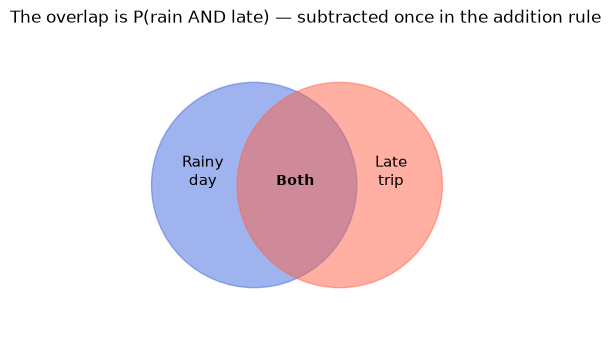

In [20]:
# =================================================================
# VISUALISATION: Overlap between two events (the addition rule)
# =================================================================
fig, ax = plt.subplots(figsize=(6, 4))
c1 = plt.Circle((0.4, 0.5), 0.3, color='royalblue', alpha=0.5)
c2 = plt.Circle((0.65, 0.5), 0.3, color='tomato', alpha=0.5)
ax.add_patch(c1); ax.add_patch(c2)
ax.text(0.25, 0.5, "Rainy\nday", ha='center', fontsize=11)
ax.text(0.8, 0.5, "Late\ntrip", ha='center', fontsize=11)
ax.text(0.52, 0.5, "Both", ha='center', fontsize=10, weight='bold')
ax.set_xlim(0, 1.1); ax.set_ylim(0.05, 0.95)
ax.set_aspect('equal'); ax.axis('off')
ax.set_title("The overlap is P(rain AND late) — subtracted once in the addition rule")
plt.show()

---
# Module 5 — Conditional Probability

**The idea:** once you know B happened, the sample space shrinks to just the "B" outcomes. Conditional probability asks: within that shrunk space, how often does A also happen?

$$P(A \mid B) = \frac{P(A \text{ and } B)}{P(B)}$$

**Matatu example:** you don't just want P(late) overall — you want P(late | it's raining), because that tells you whether rain is actually driving lateness.


In [23]:
# =================================================================
# MODULE 5  CONDITIONAL PROBABILITY
# =================================================================
np.random.seed(1)
n = 300
weather = np.random.choice(["Rainy", "Dry"], size=n, p=[0.35, 0.65])
status = np.where(
    weather == "Rainy",
    np.random.choice(["Late", "On-time"], size=n, p=[0.6, 0.4]),
    np.random.choice(["Late", "On-time"], size=n, p=[0.15, 0.85])
)

df = pd.DataFrame({"weather": weather, "status": status})
table = pd.crosstab(df["weather"], df["status"], normalize="index")
print("P(status | weather):")
print(table.round(2))

print(f"\nP(Late | Rainy) = {table.loc['Rainy','Late']:.2f}")
print(f"P(Late | Dry)   = {table.loc['Dry','Late']:.2f}")
print("→ Rain clearly raises the chance of lateness — the events are dependent.")

P(status | weather):
status   Late  On-time
weather               
Dry      0.11     0.89
Rainy    0.59     0.41

P(Late | Rainy) = 0.59
P(Late | Dry)   = 0.11
→ Rain clearly raises the chance of lateness — the events are dependent.


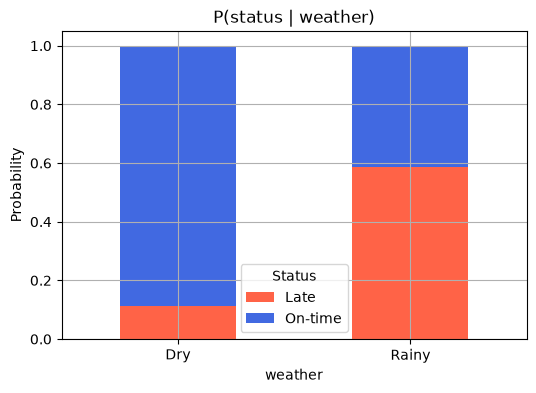

In [24]:
# =================================================================
# VISUALISATION: Conditional probabilities as bars
# =================================================================
table[["Late", "On-time"]].plot(kind="bar", stacked=True,
                                  color=["tomato", "royalblue"], figsize=(6, 4))
plt.title("P(status | weather)")
plt.ylabel("Probability")
plt.xticks(rotation=0)
plt.legend(title="Status")
plt.show()

---
# Module 6 — Bayes' Theorem & Bayesian Thinking

## The problem

You know $P(\text{breakdown} \mid \text{old matatu})$ from maintenance records. A mechanic calls about a breakdown and asks: **"what's the chance this matatu is old, given that it broke down?"** That's the *reverse* conditional — you can't just flip it, because $P(A|B) \neq P(B|A)$ in general.

## Bayes' Theorem

$$P(A \mid B) = \frac{P(B \mid A) \, P(A)}{P(B)}$$

where the denominator is expanded with the **law of total probability**:
$$P(B) = P(B \mid A)P(A) + P(B \mid \text{not } A)P(\text{not } A)$$

## Bayesian thinking

This formula isn't just a calculation trick — it's a whole philosophy of reasoning:

- Start with a **prior** belief, P(A) — what you thought before seeing evidence.
- Observe evidence B.
- Update to a **posterior** belief, P(A|B) — what you think *after* seeing evidence.

This contrasts with the classical ("frequentist") view of probability as a long-run frequency. **Bayesian thinking treats probability as a degree of belief that gets revised as new evidence arrives** — the same logic a doctor uses updating a diagnosis after a new test result, or you updating your suspicion about a matatu's age after hearing it broke down.


In [ ]:
# =================================================================
# MODULE 6  BAYES' THEOREM
# =================================================================
p_breakdown_given_old = 0.25   # 25% of old matatus break down this month
p_breakdown_given_new = 0.05   # 5% of new matatus break down
p_old = 0.40                   # PRIOR belief: 40% of the fleet is old
p_new = 0.60

p_breakdown = p_breakdown_given_old * p_old + p_breakdown_given_new * p_new
print(f"P(breakdown) = {p_breakdown:.3f}")

p_old_given_breakdown = (p_breakdown_given_old * p_old) / p_breakdown  # POSTERIOR
print(f"P(old | breakdown) = {p_old_given_breakdown:.3f}")
print(f"\nPrior belief P(old)     = {p_old:.2f}")
print(f"Posterior belief P(old | breakdown) = {p_old_given_breakdown:.2f}")
print("That jump IS Bayesian updating — new evidence reshapes the probability.")

In [ ]:
# =================================================================
# VISUALISATION: Prior vs Posterior belief
# =================================================================
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Prior\nP(old)", "Posterior\nP(old | breakdown)"],
              [p_old, p_old_given_breakdown], color=["gray", "tomato"])
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.2f}", ha='center')
ax.set_ylim(0, 1)
ax.set_title("Bayes' theorem: updating belief after seeing evidence")
plt.show()

---
# Module 7 — Random Variables & the Two Families of Distributions

**Random variable** — a function that assigns a *number* to every outcome of a random process. It turns "what happened" into "what number represents what happened."

```
Experiment: one matatu trip
Random variable X = number of passengers on that trip
```

## The two families of probability distributions

| Family | Random variable type | Countable? | Example |
|---|---|---|---|
| **Discrete** | Takes specific, separate values (0, 1, 2, 3, ...) | Yes | Number of full trips out of 10 |
| **Continuous** | Can take any value in a range | No — infinitely many possible values | Fare amount, fuel consumption, waiting time |

Every distribution you'll meet (Bernoulli, Binomial, Poisson, Uniform, Exponential, Normal, t, Chi-square) belongs to one of these two families, and that determines whether you describe it with a **PMF** or a **PDF** (next module).


In [ ]:
# =================================================================
# MODULE 7  RANDOM VARIABLES — DISCRETE vs CONTINUOUS
# =================================================================

# Discrete random variable: number of full trips out of 10 (only whole numbers possible)
full_trips = np.random.binomial(n=10, p=0.6, size=5)
print("Discrete random variable (full trips out of 10):", full_trips)

# Continuous random variable: fare amount (any decimal value possible)
fares = np.random.normal(150, 20, 5)
print("Continuous random variable (fare amount):", fares.round(2))

---
# Module 8 — PMF, PDF, CDF, PPF

These four functions describe a distribution completely — you'll use all four constantly with `scipy.stats`.

| Function | Full name | Used for | Answers |
|---|---|---|---|
| **PMF** | Probability Mass Function | Discrete variables | "What's the probability of exactly this value?" |
| **PDF** | Probability Density Function | Continuous variables | Describes relative likelihood — the *area under it* over a range gives probability |
| **CDF** | Cumulative Distribution Function | Both | "What's the probability of this value **or less**?" |
| **PPF** | Percent Point Function (inverse of CDF, aka quantile function) | Both | "What value corresponds to this percentile?" |


In [ ]:
# =================================================================
# MODULE 8  PMF, PDF, CDF, PPF IN ACTION
# =================================================================

# Continuous example: fares ~ Normal(mean=150, std=20)
mu, sigma = 150, 20
print("PDF at x=150 (peak density):", round(norm.pdf(150, mu, sigma), 4))
print("CDF at x=170 → P(fare <= 170):", round(norm.cdf(170, mu, sigma), 4))
print("PPF at 0.975 → value below which 97.5% of fares fall:", round(norm.ppf(0.975, mu, sigma), 1))

# Discrete example: matatus arriving per hour ~ Poisson(lambda=4)
lam = 4
print("\nPMF at k=3 → P(exactly 3 arrivals):", round(poisson.pmf(3, lam), 4))
print("CDF at k=3 → P(3 or fewer arrivals):", round(poisson.cdf(3, lam), 4))
print("PPF at 0.9 → the 90th percentile arrival count:", poisson.ppf(0.9, lam))

---
# Module 9 — Discrete Distributions

## Bernoulli — a single yes/no trial
Models **one** trial with two outcomes (success/failure), with success probability $p$. Example: does *this one* trip break down?

## Binomial — counting successes across many trials
Counts the number of successes in $n$ independent Bernoulli trials. Example: number of breakdowns out of 20 trips.

## Poisson — counting events over a fixed interval
Models the number of times an event happens in a fixed period, when events happen at a known average rate $\lambda$ but at random moments. Example: number of matatus arriving at a stage per hour.


In [ ]:
# =================================================================
# MODULE 9  BERNOULLI, BINOMIAL, POISSON
# =================================================================

# Bernoulli: does ONE trip break down? p = 0.3
print("Bernoulli P(breaks down) =", bernoulli.pmf(1, p=0.3))
print("Bernoulli P(doesn't break down) =", bernoulli.pmf(0, p=0.3))

# Binomial: breakdowns out of 20 trips
n, p = 20, 0.3
print("\nP(exactly 6 breakdowns out of 20) =", round(binom.pmf(6, n, p), 3))

# Poisson: matatus arriving per hour, lambda = 4
lam = 4
print("\nP(exactly 3 arrivals in an hour) =", round(poisson.pmf(3, lam), 3))
print("P(more than 6 arrivals in an hour) =", round(1 - poisson.cdf(6, lam), 3))

In [ ]:
# =================================================================
# VISUALISATION: Bernoulli, Binomial, Poisson side by side
# =================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar([0, 1], bernoulli.pmf([0, 1], 0.3), color='royalblue')
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["No", "Yes"])
axes[0].set_title("Bernoulli: does this trip break down?")

k = np.arange(0, 21)
axes[1].bar(k, binom.pmf(k, 20, 0.3), color='seagreen')
axes[1].set_title("Binomial: breakdowns out of 20 trips")

k2 = np.arange(0, 15)
axes[2].bar(k2, poisson.pmf(k2, 4), color='tomato')
axes[2].set_title("Poisson: arrivals per hour (λ=4)")
plt.tight_layout()
plt.show()

---
# Module 10 — Continuous Distributions

## Uniform — every value in a range is equally likely
Example: if matatus depart every 10 minutes, your arrival time within that window is uniformly distributed.

## Exponential — time until the next random event
Example: waiting time until the next matatu arrives. Closely linked to Poisson — if arrivals follow a Poisson process, the *gaps between* arrivals follow an Exponential distribution.

## Normal — the bell curve
Already familiar from the linear algebra notebook: symmetric, defined by mean $\mu$ and standard deviation $\sigma$. Shows up constantly — and, thanks to the Central Limit Theorem (Module 14), even shows up for *averages* of non-normal data.


In [ ]:
# =================================================================
# MODULE 10  UNIFORM, EXPONENTIAL, NORMAL
# =================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

xs = np.linspace(0, 10, 200)
axes[0].plot(xs, uniform.pdf(xs, loc=0, scale=10), color='royalblue')
axes[0].set_title("Uniform: arrival time in a 10-min window")

xs2 = np.linspace(0, 30, 200)
axes[1].plot(xs2, expon.pdf(xs2, scale=8), color='seagreen')
axes[1].set_title("Exponential: waiting time for next matatu")

xs3 = np.linspace(80, 220, 200)
axes[2].plot(xs3, norm.pdf(xs3, 150, 20), color='tomato')
axes[2].set_title("Normal: fare amount")
plt.tight_layout()
plt.show()

print("P(wait more than 15 min) =", round(1 - expon.cdf(15, scale=8), 3))

---
# Module 11 — Standardisation & the Z-score

## The problem

A fare of 180 KES and a fuel reading of 5.2L are on totally different scales. How do you compare "how unusual" each one is?

## The solution: standardise

Convert any value to a **z-score** — how many standard deviations it is from the mean:
$$z = \frac{x - \mu}{\sigma}$$

A z-score of 0 means "exactly average." A z-score of +2 means "2 standard deviations above average" — under a normal distribution, that's already quite unusual (only ~2.5% of values go higher). Standardising puts every variable on the same universal scale, which is essential for comparing across features and is the backbone of z-tests.


In [ ]:
# =================================================================
# MODULE 11  STANDARDISATION AND Z-SCORE
# =================================================================
fares = np.random.normal(150, 20, 10)
z = (fares - fares.mean()) / fares.std()

for f, zi in zip(fares.round(1), z.round(2)):
    flag = "  ← unusually high" if zi > 2 else ("  ← unusually low" if zi < -2 else "")
    print(f"fare={f:>6}   z={zi:>5}{flag}")

---
# Module 12 — The t-distribution and Chi-square Distribution

Both of these are **sampling distributions** — they don't describe your raw data, they describe a *statistic computed from a sample*, and they exist because working with samples (instead of the whole population) introduces extra uncertainty.

## t-distribution
Looks like the normal distribution but with **fatter tails**. Used instead of the normal distribution whenever you estimate the population standard deviation from a *small sample* rather than knowing it exactly. Fatter tails = more caution, because a small sample gives a less reliable estimate. As sample size grows, the t-distribution converges to the normal distribution.

## Chi-square distribution
Always positive, right-skewed. Comes from summing squared standardised values. It's the engine behind the chi-square test (categorical relationships) and tests about variance.


In [ ]:
# =================================================================
# MODULE 12  T-DISTRIBUTION vs CHI-SQUARE vs NORMAL
# =================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

xs = np.linspace(-4, 4, 200)
axes[0].plot(xs, norm.pdf(xs), label="Normal", color='black')
axes[0].plot(xs, t.pdf(xs, df=2), label="t (df=2)", color='tomato', linestyle='--')
axes[0].plot(xs, t.pdf(xs, df=20), label="t (df=20)", color='royalblue', linestyle=':')
axes[0].legend()
axes[0].set_title("t-distribution: fatter tails at low df,\napproaches Normal as df grows")

xs2 = np.linspace(0, 20, 200)
axes[1].plot(xs2, chi2.pdf(xs2, df=2), label="df=2")
axes[1].plot(xs2, chi2.pdf(xs2, df=4), label="df=4")
axes[1].plot(xs2, chi2.pdf(xs2, df=8), label="df=8")
axes[1].legend()
axes[1].set_title("Chi-square distribution at different degrees of freedom")
plt.tight_layout()
plt.show()

---
# Module 13 — Why Probability Distributions Matter: Two Worked Examples

**Example 1 — Inventory planning with Poisson.** If matatus break down at an average rate of 3 per week, modelling breakdowns as Poisson(λ=3) lets you calculate "what's the chance of needing 6+ spare parts this week?" *before* it happens — turning a vague worry into a stockable number.

**Example 2 — Fraud/anomaly detection with the Normal distribution.** If fares are normally distributed around 150 KES, any fare with a z-score beyond ±3 is a near-impossible value under normal operation — worth flagging for review. Without a distribution model, "unusual" is just a gut feeling; with one, it's a precise, defensible rule.

**The general point:** a probability distribution turns a real-world random process into a mathematical object you can *query* — compute exact probabilities, set data-driven thresholds, and plan for uncertainty instead of just reacting to it.


In [ ]:
# =================================================================
# MODULE 13  TWO WORKED EXAMPLES
# =================================================================

# Example 1: inventory planning
lam = 3
print("Breakdowns/week ~ Poisson(3)")
print("P(need 6 or more spare parts this week) =", round(1 - poisson.cdf(5, lam), 3))

# Example 2: anomaly detection via z-score
mu, sigma = 150, 20
suspicious_fare = 230
z_score = (suspicious_fare - mu) / sigma
print(f"\nFare of {suspicious_fare} KES has z = {z_score:.2f}")
print("P(a normal fare would be this high or higher) =", round(1 - norm.cdf(suspicious_fare, mu, sigma), 5))
print("→ Extremely unlikely under normal operation. Flag for review.")

---
# Module 14 — The Central Limit Theorem (CLT)

## The problem

Waiting times for a matatu are skewed, not bell-shaped — most people wait briefly, a few wait a long time. Yet almost every test ahead (t-tests included) leans on the normal distribution. How is that valid on skewed data?

## The CLT, in one sentence

**No matter the shape of the original population, if you repeatedly take reasonably large samples and compute their means, the distribution of those sample means becomes approximately normal.**

## When is the CLT actually used?

- Justifying the use of z/t-tests on data that isn't itself normally distributed.
- Building confidence intervals for a mean from any population shape.
- Any time you're reasoning about a **sample mean** (or sum) rather than individual raw values — polling, quality control, A/B testing.

**Bonus fact:** the spread of the sampling distribution — the standard error — shrinks as sample size grows: $SE = \sigma / \sqrt{n}$.


In [ ]:
# =================================================================
# MODULE 14  CENTRAL LIMIT THEOREM
# =================================================================
population = np.random.exponential(scale=8, size=100_000)   # skewed waiting times
print("Population mean:", round(population.mean(), 2), " — skewed, NOT bell-shaped")

sample_size, n_samples = 40, 2000
sample_means = np.array([
    population[np.random.choice(len(population), sample_size, replace=False)].mean()
    for _ in range(n_samples)
])

print("Sample means: mean =", round(sample_means.mean(), 2), " std =", round(sample_means.std(), 2))
print("CLT-predicted SE (σ/√n) =", round(population.std() / np.sqrt(sample_size), 2))

In [ ]:
# =================================================================
# VISUALISATION: Skewed population vs normal-shaped sampling distribution
# =================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(population, bins=50, color="tomato")
axes[0].set_title("Population: waiting times (skewed)")
axes[1].hist(sample_means, bins=40, color="royalblue")
axes[1].set_title(f"Sampling distribution of the mean (n={sample_size})")
plt.tight_layout()
plt.show()

---
# Module 15 — Standard Error vs Standard Deviation

These two are constantly confused, but they measure different things:

| | Standard Deviation (SD) | Standard Error (SE) |
|---|---|---|
| Measures spread of | **Individual data points** in a sample/population | **The sample mean itself**, across repeated samples |
| Formula | $\sigma = \sqrt{\frac{\sum (x_i - \bar x)^2}{n-1}}$ | $SE = \frac{\sigma}{\sqrt{n}}$ |
| Shrinks with bigger n? | No — it reflects the data's natural variability | Yes — bigger samples pin down the mean more precisely |
| Used for | Describing the spread of raw fares | Building confidence intervals and t-tests around the *mean* fare |


In [ ]:
# =================================================================
# MODULE 15  STANDARD DEVIATION vs STANDARD ERROR
# =================================================================
sample = np.random.normal(150, 20, 40)
sd = sample.std(ddof=1)
se = sd / np.sqrt(len(sample))

print("Standard deviation (spread of individual fares):", round(sd, 2))
print("Standard error (spread of the SAMPLE MEAN across repeated samples):", round(se, 2))
print("\nNotice: SE is always smaller — it describes how well the MEAN is pinned down, not the raw spread.")

---
# Module 16 — Confidence Intervals

## What it is

A **confidence interval (CI)** is a range of plausible values for a population parameter (like the true mean fare), built around your sample estimate, at a stated **confidence level** (usually 95%).

**Correct interpretation:** if you repeated this sampling process many times and built a CI each time, about 95% of those intervals would contain the true population mean. (It does *not* mean "95% probability the true mean is in this one interval.")

## Relationship to the Normal distribution

The CI is built directly from the standard error and a critical value from the normal (or t) distribution:
$$CI = \bar{x} \pm (\text{critical value}) \times SE$$

This is only valid because — thanks to the CLT — the sample mean's distribution is approximately normal, so we know exactly how far out a 95% range should stretch.


In [ ]:
# =================================================================
# MODULE 16  CONFIDENCE INTERVALS
# =================================================================
sample = np.random.normal(150, 20, 40)
mean = sample.mean()
se = sample.std(ddof=1) / np.sqrt(len(sample))

confidence = 0.95
t_crit = stats.t.ppf((1 + confidence) / 2, df=len(sample) - 1)
margin = t_crit * se
ci = (mean - margin, mean + margin)

print(f"Sample mean fare = {mean:.1f}")
print(f"95% CI for the true mean fare: ({ci[0]:.1f}, {ci[1]:.1f})")

In [ ]:
# =================================================================
# VISUALISATION: The confidence interval around the sample mean
# =================================================================
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(mean, 0, xerr=margin, fmt='o', color='royalblue', capsize=8, markersize=8)
ax.set_yticks([])
ax.set_xlabel("Fare (KES)")
ax.set_title(f"95% CI: {ci[0]:.1f} to {ci[1]:.1f}, centred on sample mean {mean:.1f}")
plt.show()

---
# Module 17 — Hypothesis Testing

## What it is

A structured procedure for deciding whether a pattern observed in a **sample** reflects something real in the **population**, or could just be random noise.

## Why it matters / where it's applied

Anywhere a decision hinges on data instead of gut feeling: does a new pricing policy actually raise revenue? Does a new brake pad reduce failure rates? Is a drug more effective than a placebo? Hypothesis testing gives you a defensible yes/no with a quantified risk of being wrong.

## Which distribution it uses, and why

| Situation | Distribution used | Why |
|---|---|---|
| Comparing a mean, population SD unknown, sample not huge | **t-distribution** | Extra uncertainty from estimating SD from a small sample → fatter tails |
| Comparing a mean, population SD known or n very large | **Normal (z)** | The CLT guarantees the sample mean is normal |
| Testing relationships between categorical variables / variance | **Chi-square** | Built from sums of squared standardised values |

## The logic of hypothesis testing

You never directly prove your theory. Instead, you **assume the boring explanation is true (H₀)**, then check: "if H₀ really were true, how unlikely is it that I'd see data this extreme?" If that would be very unlikely, you doubt H₀ instead of accepting an absurd coincidence — this is reasoning by contradiction, not direct proof.

## The 5 steps of hypothesis testing

1. **State H₀** (nothing interesting happening) and **H₁** (what you suspect is true).
2. **Choose a significance level, α** (usually 0.05) — your tolerance for wrongly rejecting a true H₀.
3. **Choose the right test and compute the test statistic** (t, z, or chi-square) from your sample.
4. **Compute the p-value** — the probability of a result this extreme (or more) *if H₀ were true*.
5. **Decide:** if p-value < α, reject H₀. Otherwise, fail to reject H₀.

## P-values

The p-value is **not** "the probability H₀ is true." It's the probability of seeing data at least this extreme, assuming H₀ **is** true. A small p-value means your data would be a surprising coincidence under H₀ — evidence against it.


In [ ]:
# =================================================================
# MODULE 17  THE LOGIC OF HYPOTHESIS TESTING, ILLUSTRATED
# =================================================================
# H0: the fleet's average fuel use = 4.0L (manufacturer's claim)
# H1: it is different

sample_fuel = np.random.normal(4.3, 0.6, 25)
t_stat, p_val = stats.ttest_1samp(sample_fuel, popmean=4.0)

print("Step 1: H0: mean = 4.0L,  H1: mean != 4.0L")
print("Step 2: alpha = 0.05")
print(f"Step 3: test statistic t = {t_stat:.2f}  (t-distribution, since population SD is unknown)")
print(f"Step 4: p-value = {p_val:.4f}")
alpha = 0.05
print("Step 5:", "Reject H0" if p_val < alpha else "Fail to reject H0")

---
# Module 18 — Type I and Type II Errors

Every decision in hypothesis testing carries a risk of being wrong, in one of two ways:

| | H₀ is actually True | H₀ is actually False |
|---|---|---|
| **You reject H₀** | ❌ **Type I error** (false positive) — probability = α | ✅ Correct decision |
| **You fail to reject H₀** | ✅ Correct decision | ❌ **Type II error** (false negative) — probability = β |

- **Type I error**: concluding there's an effect when there isn't one (e.g. thinking a new policy works when it's really no different).
- **Type II error**: missing a real effect that actually exists (e.g. thinking a new policy doesn't work when it actually does).

There's a trade-off: lowering α (being stricter about Type I errors) generally raises the risk of Type II errors, unless you also increase your sample size.

**The critical value / critical region** is the cutoff on the test statistic's distribution beyond which you reject H₀ — everything past that point is the "rejection region," and it's exactly sized so that the area under the curve there equals α.


In [ ]:
# =================================================================
# MODULE 18  TYPE I / TYPE II ERRORS AND THE CRITICAL REGION
# =================================================================
dof = len(sample_fuel) - 1
alpha = 0.05
crit = stats.t.ppf(1 - alpha/2, dof)   # two-tailed critical value

xs = np.linspace(-4, 4, 300)
ys = stats.t.pdf(xs, dof)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, ys, color='black')
ax.fill_between(xs, ys, where=(np.abs(xs) >= crit), color='tomato', alpha=0.4,
                 label=f"Rejection region (Type I risk = α={alpha})")
ax.axvline(t_stat, color='royalblue', lw=2, label=f"Observed t = {t_stat:.2f}")
ax.set_title("Critical region: reject H0 if the observed statistic lands here")
ax.legend()
plt.show()

print(f"Critical value (two-tailed, df={dof}) = ±{crit:.2f}")
print("If the true mean really were 4.0L, there is still a", alpha, "chance we'd wrongly reject it (Type I).")

---
# Module 19 — One-Sample t-test

## When to use it

You have **one sample** and want to compare its mean against a **known or claimed value**.

**Matatu example:** the manufacturer claims average fuel consumption is 4.0L per trip. You measure 25 real trips — is your fleet's actual consumption significantly different?


In [ ]:
# =================================================================
# MODULE 19  ONE-SAMPLE T-TEST
# =================================================================
sample_fuel = np.random.normal(loc=4.3, scale=0.6, size=25)
t_stat, p_val = stats.ttest_1samp(sample_fuel, popmean=4.0)

print(f"Sample mean = {sample_fuel.mean():.2f}L  (claimed: 4.0L)")
print(f"t = {t_stat:.2f},  p = {p_val:.4f}")
print("Reject H0" if p_val < 0.05 else "Fail to reject H0")

---
# Module 20 — Two-Sample t-test

## When to use it

You have **two independent groups** and want to compare their means.

**Matatu example:** are afternoon fares actually higher than morning fares, or is that just random sample-to-sample variation?


In [ ]:
# =================================================================
# MODULE 20  TWO-SAMPLE T-TEST
# =================================================================
morning_fares   = np.random.normal(150, 20, 30)
afternoon_fares = np.random.normal(165, 22, 30)

t_stat2, p_val2 = stats.ttest_ind(morning_fares, afternoon_fares)
print(f"Morning mean   = {morning_fares.mean():.1f}")
print(f"Afternoon mean = {afternoon_fares.mean():.1f}")
print(f"t = {t_stat2:.2f},  p = {p_val2:.4f}")
print("Reject H0 → fares genuinely differ" if p_val2 < 0.05 else "Fail to reject H0")

In [ ]:
# =================================================================
# VISUALISATION: Comparing the two groups directly
# =================================================================
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([morning_fares, afternoon_fares], labels=["Morning", "Afternoon"],
           patch_artist=True, boxprops=dict(facecolor="royalblue", alpha=0.5))
ax.set_title(f"Fare distributions  (p = {p_val2:.4f})")
ax.set_ylabel("Fare (KES)")
plt.show()

---
# Module 21 — Chi-Square Test of Independence

## When to use it

Both variables are **categorical** — t-tests don't apply here because there's no mean to compare, only counts.

**Matatu example:** does a matatu's age group (Old / New) relate to whether it broke down this month?


In [ ]:
# =================================================================
# MODULE 21  CHI-SQUARE TEST
# =================================================================
data = pd.DataFrame({
    "age_group": ["Old"] * 80 + ["New"] * 120,
    "broke_down": (["Yes"] * 30 + ["No"] * 50) + (["Yes"] * 15 + ["No"] * 105)
})
table = pd.crosstab(data["age_group"], data["broke_down"])
print("Observed counts:")
print(table)

chi2_stat, p_val3, dof, expected = stats.chi2_contingency(table)
print(f"\nchi2 = {chi2_stat:.2f}, p = {p_val3:.4f}, dof = {dof}")
print("Reject H0 → age group and breakdowns ARE related" if p_val3 < 0.05 else "Fail to reject H0")

In [ ]:
# =================================================================
# VISUALISATION: Observed counts as a heatmap
# =================================================================
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(table.values, cmap="Blues")
ax.set_xticks(range(len(table.columns))); ax.set_xticklabels(table.columns)
ax.set_yticks(range(len(table.index))); ax.set_yticklabels(table.index)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax.text(j, i, table.values[i, j], ha="center", va="center", fontsize=13)
ax.set_title(f"Age group vs breakdown  (p = {p_val3:.4f})")
plt.colorbar(im, label="Count")
plt.show()

---
# Module 22 — A/B Testing

## What it is

A/B testing is hypothesis testing applied to comparing **two versions** of something — a control (A) and a variant (B) — to see which performs better, usually on a proportion (conversion rate, profitability rate) or a mean.

**Key vocabulary:**
- **Test statistic** — the z or t value computed from the two groups' data.
- **Critical value** — the cutoff the test statistic must pass to count as significant.
- **Significance level (α)** — usually 0.05, your Type I error tolerance.
- **Confidence level** — $1 - \alpha$; e.g. α=0.05 pairs with a 95% confidence level.

**Matatu example:** does pricing Policy B produce a higher rate of profitable trips than Policy A?


In [ ]:
# =================================================================
# MODULE 22  A/B TESTING (TWO-PROPORTION Z-TEST)
# =================================================================
n_A, n_B = 400, 400
conv_A = np.random.binomial(1, 0.50, n_A)   # Policy A: profitable trip rate
conv_B = np.random.binomial(1, 0.63, n_B)   # Policy B

p_A, p_B = conv_A.mean(), conv_B.mean()
p_pool = (conv_A.sum() + conv_B.sum()) / (n_A + n_B)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1/n_A + 1/n_B))
z_stat = (p_B - p_A) / se_pool
p_val4 = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(f"Policy A profitable rate: {p_A:.2f}")
print(f"Policy B profitable rate: {p_B:.2f}")
print(f"Test statistic z = {z_stat:.2f},  p = {p_val4:.5f}")
print("Reject H0 → Policy B is significantly better" if p_val4 < 0.05 else "Fail to reject H0")

---
# Module 23 — Confusion Matrix: Accuracy, Precision, Recall

## What it is

Once you build a classifier (e.g. predicting "will this matatu break down?"), you need a way to score how good its predictions are. The **confusion matrix** lays out every combination of predicted vs actual outcome:

| | Predicted: No | Predicted: Yes |
|---|---|---|
| **Actual: No**  | True Negative (TN) | False Positive (FP) |
| **Actual: Yes** | False Negative (FN) | True Positive (TP) |

## Metrics built from it

- **Accuracy** = $\frac{TP+TN}{TP+TN+FP+FN}$ — overall, how often is the model right? Misleading when classes are imbalanced.
- **Precision** = $\frac{TP}{TP+FP}$ — of everything predicted "Yes," how much was actually "Yes"? High precision = few false alarms.
- **Recall** = $\frac{TP}{TP+FN}$ — of everything actually "Yes," how much did the model catch? High recall = few missed cases.


In [ ]:
# =================================================================
# MODULE 23  CONFUSION MATRIX, PRECISION, RECALL, ACCURACY
# =================================================================
n = 200
actual = np.random.choice([1, 0], size=n, p=[0.3, 0.7])   # 1 = actually breaks down
predicted = actual.copy()
flip_idx = np.random.choice(n, size=30, replace=False)
predicted[flip_idx] = 1 - predicted[flip_idx]             # simulate prediction errors

cm = confusion_matrix(actual, predicted)
print("Confusion matrix:\n", cm)
print("Accuracy :", round(accuracy_score(actual, predicted), 2))
print("Precision:", round(precision_score(actual, predicted), 2))
print("Recall   :", round(recall_score(actual, predicted), 2))

In [ ]:
# =================================================================
# VISUALISATION: Confusion matrix heatmap
# =================================================================
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred: No", "Pred: Yes"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual: No", "Actual: Yes"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax.set_title("Confusion matrix: breakdown prediction")
plt.show()

---
# Module 24 — Variance, Covariance, Correlation

- **Variance** — the average squared distance of data points from their mean. Measures spread of **one** variable.
$$\text{Var}(X) = \frac{\sum (x_i - \bar x)^2}{n - 1}$$

- **Covariance** — measures whether **two** variables move together (positive), oppositely (negative), or unrelated (near zero). Its scale depends on the units of the variables, which makes raw values hard to compare.
$$\text{Cov}(X, Y) = \frac{\sum (x_i - \bar x)(y_i - \bar y)}{n - 1}$$

- **Correlation** — covariance rescaled to always fall between -1 and 1, making strength of relationship directly comparable across variable pairs.
$$r = \frac{\text{Cov}(X, Y)}{\sigma_X \sigma_Y}$$


In [ ]:
# =================================================================
# MODULE 24  VARIANCE, COVARIANCE, CORRELATION
# =================================================================
trips = np.random.normal(12, 3, 100)
fares = trips * 15 + np.random.normal(0, 5, 100)

print("Variance(trips)             =", round(np.var(trips, ddof=1), 2))
print("Covariance(trips, fares)    =", round(np.cov(trips, fares)[0, 1], 2))
print("Correlation(trips, fares)   =", round(np.corrcoef(trips, fares)[0, 1], 2))

In [ ]:
# =================================================================
# VISUALISATION: What correlation looks like
# =================================================================
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(trips, fares, alpha=0.6, color='royalblue')
ax.set_xlabel("Trips")
ax.set_ylabel("Fare (KES)")
ax.set_title(f"Strong positive correlation: r = {np.corrcoef(trips, fares)[0,1]:.2f}")
plt.show()

---
# Module 25 — Skewness & Kurtosis

- **Skewness** — measures asymmetry. Zero = symmetric (like the normal distribution). Positive skew = a long tail stretching to the right (e.g. waiting times: most short, a few very long). Negative skew = long tail to the left.

- **Kurtosis** — measures "tailedness" — how much of the data sits in extreme outliers vs the centre, relative to a normal distribution. Excess kurtosis of 0 matches normal; positive means heavier tails (more extreme outliers than normal); negative means lighter tails.


In [ ]:
# =================================================================
# MODULE 25  SKEWNESS AND KURTOSIS
# =================================================================
waiting_times = np.random.exponential(scale=8, size=1000)   # right-skewed
fares_normal  = np.random.normal(150, 20, 1000)              # roughly symmetric

print("Waiting times — skewness:", round(stats.skew(waiting_times), 2),
      " kurtosis:", round(stats.kurtosis(waiting_times), 2))
print("Fares          — skewness:", round(stats.skew(fares_normal), 2),
      " kurtosis:", round(stats.kurtosis(fares_normal), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(waiting_times, bins=40, color='tomato')
axes[0].set_title("Positively skewed: waiting times")
axes[1].hist(fares_normal, bins=40, color='royalblue')
axes[1].set_title("Roughly symmetric: fares")
plt.tight_layout()
plt.show()

---
# Module 26 — The Cardinal Sin: Correlation ≠ Causation

A strong correlation between two variables tells you they move together — it does **not** tell you one causes the other. There are always three possibilities:

1. **A causes B** (rain causes lateness)
2. **B causes A** (reverse causation)
3. **A confounding variable C causes both** (e.g. matatus that do more trips per day both earn more fare AND use more fuel — trips-per-day is the hidden driver of both, they don't cause each other)

**Matatu example:** fare revenue and fuel consumption are highly correlated across the fleet. It's tempting to say "spending more on fuel causes higher revenue" — but the real driver is simply **more trips**, which independently pushes both numbers up. Treating this correlation as causation could lead to the wrong conclusion (e.g. "just burn more fuel to make more money").

**The rule to live by:** correlation can be a clue that motivates further investigation (e.g. a controlled A/B test), but on its own it is never proof of cause and effect.


In [ ]:
# =================================================================
# MODULE 26  CORRELATION IS NOT CAUSATION — A CONFOUNDING EXAMPLE
# =================================================================
trips_per_day = np.random.normal(15, 4, 200)                        # the hidden common driver
fuel_used     = trips_per_day * 0.4 + np.random.normal(0, 0.5, 200)  # driven by trips
revenue       = trips_per_day * 18  + np.random.normal(0, 10, 200)   # also driven by trips

print("Correlation(fuel_used, revenue) =", round(np.corrcoef(fuel_used, revenue)[0, 1], 2))
print("→ Strong correlation, but fuel does not CAUSE revenue.")
print("Both are driven by the confounder: trips_per_day.")
print("Correlation(trips_per_day, fuel_used) =", round(np.corrcoef(trips_per_day, fuel_used)[0, 1], 2))
print("Correlation(trips_per_day, revenue)   =", round(np.corrcoef(trips_per_day, revenue)[0, 1], 2))

---
# Quick Reference — Everything in One Table

| What you want to do | Tool | Code |
|---|---|---|
| Probability of A or B | Addition rule | `P(A) + P(B) - P(A and B)` |
| Probability of A and B (independent) | Multiplication rule | `P(A) * P(B)` |
| Probability of A given B | Conditional probability | `pd.crosstab(x, y, normalize="index")` |
| Reverse a conditional probability | Bayes' theorem | `(P(B\\|A) * P(A)) / P(B)` |
| Single yes/no trial | Bernoulli | `bernoulli.pmf(k, p)` |
| Count of successes in n trials | Binomial | `binom.pmf(k, n, p)` |
| Count of events in a fixed interval | Poisson | `poisson.pmf(k, lam)` |
| Equal likelihood over a range | Uniform | `uniform.pdf(x, loc, scale)` |
| Time until next random event | Exponential | `expon.pdf(x, scale)` |
| Bell-shaped continuous variable | Normal | `norm.pdf(x, mean, std)` |
| Small-sample mean comparisons | t-distribution | `t.ppf(...)`, `ttest_1samp`, `ttest_ind` |
| Categorical relationship / variance tests | Chi-square | `chi2_contingency(table)` |
| Standardise a value | Z-score | `(x - mean) / std` |
| Distribution of sample means | CLT | draw many samples, plot `sample_means` |
| Spread of the sample mean | Standard error | `std / sqrt(n)` |
| Range of plausible values for the mean | Confidence interval | `stats.t.interval(conf, df, loc, scale)` |
| Compare one sample's mean to a known value | One-sample t-test | `ttest_1samp(sample, popmean)` |
| Compare means of two independent groups | Two-sample t-test | `ttest_ind(group1, group2)` |
| Compare two proportions (A/B test) | Two-proportion z-test | pooled SE + `norm.cdf` |
| Test if two categorical variables are related | Chi-square test | `chi2_contingency(table)` |
| Score a classifier | Confusion matrix | `confusion_matrix`, `precision_score`, `recall_score`, `accuracy_score` |
| Spread of one variable | Variance | `np.var(x, ddof=1)` |
| Do two variables move together | Covariance | `np.cov(x, y)` |
| Standardised strength of relationship | Correlation | `np.corrcoef(x, y)` |
| Asymmetry of a distribution | Skewness | `scipy.stats.skew(x)` |
| Tailedness of a distribution | Kurtosis | `scipy.stats.kurtosis(x)` |
